In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Libraries imported successfully!")

Libraries imported successfully!


In [37]:
df = pd.read_csv("diabetes.csv")
print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0  33.6                     0.627   50        1
1            1       85             66             29        0  26.6                     0.351   31        0
2            8      183             64              0        0  23.3                     0.672   32        1
3            1       89             66             23       94  28.1                     0.167   21        0
4            0      137             40             35      168  43.1                     2.288   33        1


In [38]:
print("First 5 rows:")
print(df.head())
print("\\nLast 5 rows:")
print(df.tail())
print("\\nA random sample of 5 rows:")
print(df.sample(5, random_state=42))

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0  33.6                     0.627   50        1
1            1       85             66             29        0  26.6                     0.351   31        0
2            8      183             64              0        0  23.3                     0.672   32        1
3            1       89             66             23       94  28.1                     0.167   21        0
4            0      137             40             35      168  43.1                     2.288   33        1
\nLast 5 rows:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
763           10      101             76             48      180  32.9                     0.171   63        0
764            2      122             70             27        0  36.8                     0.34

In [39]:
print("Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\\nColumn names:")
print(df.columns.tolist())

Shape: (768, 9)
Number of rows: 768
Number of columns: 9
\nColumn names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [41]:
print(df.describe().round(2))

       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  DiabetesPedigreeFunction     Age  Outcome
count       768.00   768.00         768.00         768.00   768.00  768.00                    768.00  768.00   768.00
mean          3.85   120.89          69.11          20.54    79.80   31.99                      0.47   33.24     0.35
std           3.37    31.97          19.36          15.95   115.24    7.88                      0.33   11.76     0.48
min           0.00     0.00           0.00           0.00     0.00    0.00                      0.08   21.00     0.00
25%           1.00    99.00          62.00           0.00     0.00   27.30                      0.24   24.00     0.00
50%           3.00   117.00          72.00          23.00    30.50   32.00                      0.37   29.00     0.00
75%           6.00   140.25          80.00          32.00   127.25   36.60                      0.63   41.00     1.00
max          17.00   199.00         122.00          99.0

Outcome
0    500
1    268
Name: count, dtype: int64
\nPercentage:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


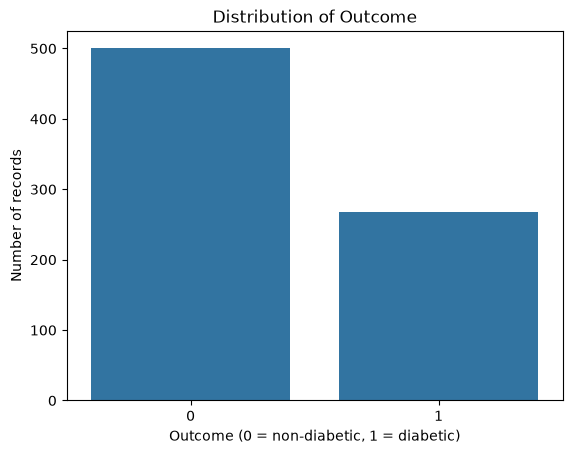

In [42]:
print(df["Outcome"].value_counts().sort_index())
print("\\nPercentage:")
print((df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(1))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Outcome")
plt.xlabel("Outcome (0 = non-diabetic, 1 = diabetic)")
plt.ylabel("Number of records")
plt.show()

In [43]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)
missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})
print(missing_report)

                          Missing_Count  Missing_Percent
Pregnancies                           0              0.0
Glucose                               0              0.0
BloodPressure                         0              0.0
SkinThickness                         0              0.0
Insulin                               0              0.0
BMI                                   0              0.0
DiabetesPedigreeFunction              0              0.0
Age                                   0              0.0
Outcome                               0              0.0


In [44]:
zero_columns = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"
]
print(df[zero_columns].eq(0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [45]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [46]:
quality_report = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Values": df.isnull().sum(),
    "Zero_Values": (df == 0).sum(),
    "Unique_Values": df.nunique()
})
print(quality_report)

                         Data_Type  Missing_Values  Zero_Values  Unique_Values
Pregnancies                  int64               0          111             17
Glucose                      int64               0            5            136
BloodPressure                int64               0           35             47
SkinThickness                int64               0          227             51
Insulin                      int64               0          374            186
BMI                        float64               0           11            248
DiabetesPedigreeFunction   float64               0            0            517
Age                          int64               0            0             52
Outcome                      int64               0          500              2


In [47]:
df_clean = df.copy()
measurement_columns = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"
]
df_clean[measurement_columns] = (
    df_clean[measurement_columns].replace(0, np.nan)
)
print(df_clean[measurement_columns].isnull().sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [48]:
for col in measurement_columns:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)
    print(col, "median =", round(median_value, 2))
print("\\nMissing values after filling:")
print(df_clean[measurement_columns].isnull().sum())

Glucose median = 117.0
BloodPressure median = 72.0
SkinThickness median = 29.0
Insulin median = 125.0
BMI median = 32.3
\nMissing values after filling:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


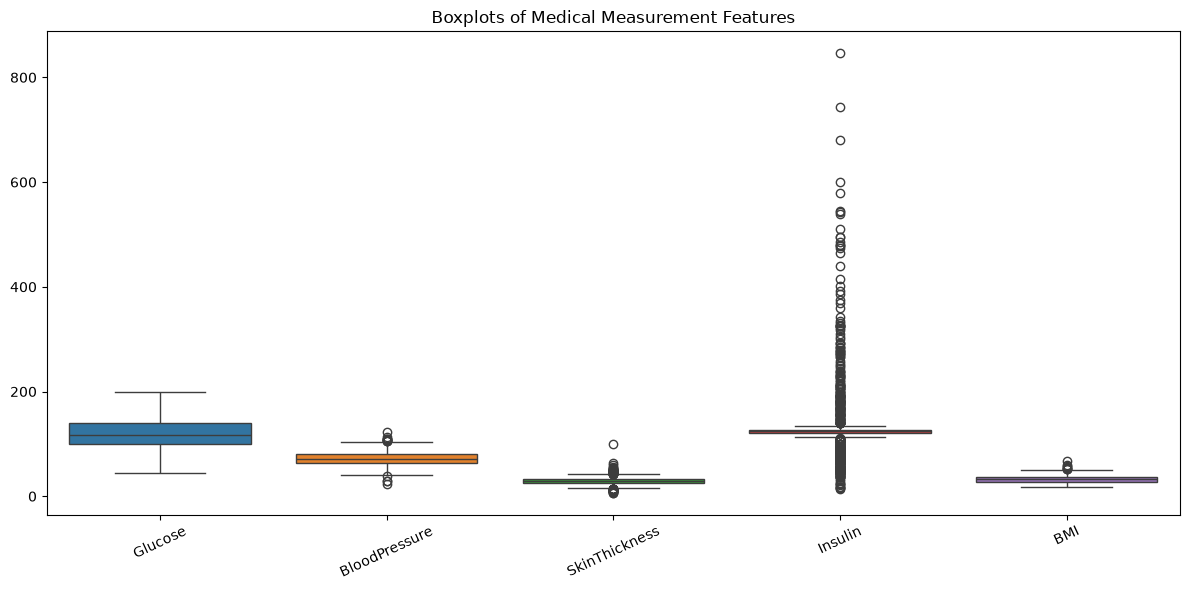

In [49]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean[measurement_columns])
plt.title("Boxplots of Medical Measurement Features")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

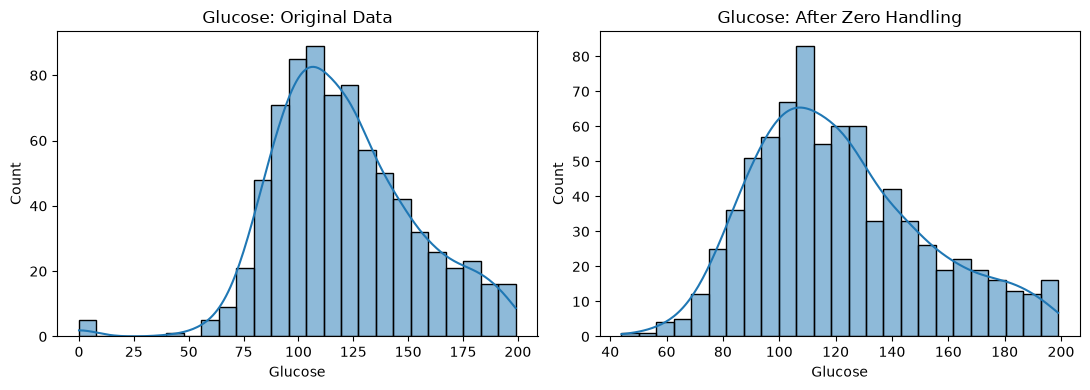

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Glucose"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Glucose: Original Data")
sns.histplot(df_clean["Glucose"], bins=25, kde=True, ax=axes[1])
axes[1].set_title("Glucose: After Zero Handling")
plt.tight_layout()
plt.show()

In [51]:
df_clean.to_csv("diabetes_cleaned.csv", index=False)
print("Cleaned dataset exported successfully!")
print("New shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

Cleaned dataset exported successfully!
New shape: (768, 9)
Missing values: 0


In [52]:
X = df[[
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age"
]].copy()
y = df["Outcome"].copy()
# Convert only the selected zero placeholders to NaN in X
X[measurement_columns] = X[measurement_columns].replace(0, np.nan)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\\nTarget distribution:")
print(y.value_counts().sort_index())

X shape: (768, 8)
y shape: (768,)
\nTarget distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (614, 8)
X_test : (154, 8)
y_train: (614,)
y_test : (154,)


In [54]:
preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape :", X_test_processed.shape)
print("Any NaN in training data:",
      np.isnan(X_train_processed).sum())
print("Any NaN in testing data:",
      np.isnan(X_test_processed).sum())

Processed training shape: (614, 8)
Processed testing shape : (154, 8)
Any NaN in training data: 0
Any NaN in testing data: 0


In [55]:
processed_train_df = pd.DataFrame(
    X_train_processed,
    columns=X_train.columns
)
print(processed_train_df.describe().loc[["mean", "std"]].round(2))

      Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI  DiabetesPedigreeFunction  Age
mean         -0.0     -0.0            0.0           -0.0     -0.0  0.0                      -0.0 -0.0
std           1.0      1.0            1.0            1.0      1.0  1.0                       1.0  1.0


In [56]:
train_export = processed_train_df.copy()
train_export["Outcome"] = y_train.reset_index(drop=True)
test_export = pd.DataFrame(
    X_test_processed,
    columns=X_test.columns
)
test_export["Outcome"] = y_test.reset_index(drop=True)
train_export.to_csv("diabetes_train.csv", index=False)
test_export.to_csv("diabetes_test.csv", index=False)
print("Training and testing files exported.")
print("Train file shape:", train_export.shape)
print("Test file shape :", test_export.shape)

Training and testing files exported.
Train file shape: (614, 9)
Test file shape : (154, 9)


In [57]:
top_insulin = df.nlargest(5, "Insulin")[
    ["Insulin", "Glucose", "BMI", "Age", "Outcome"]
]
print("5 Highest Insulin Value records:")
print(top_insulin)

5 Highest Insulin Value records:
     Insulin  Glucose   BMI  Age  Outcome
13       846      189  30.1   59        1
228      744      197  36.7   31        0
247      680      165  52.3   23        0
584      600      124  28.7   52        1
409      579      172  42.4   28        1


In [ ]:
measurement_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]
zero_percentage = (df[measurement_columns].eq(0).mean() * 100).round(2)
print("Zero value percentage of the five columns")
print(zero_percentage)

Zero value percentage of the five columns
Glucose           0.65
BloodPressure     4.56
SkinThickness    29.56
Insulin          48.70
BMI               1.43
dtype: float64


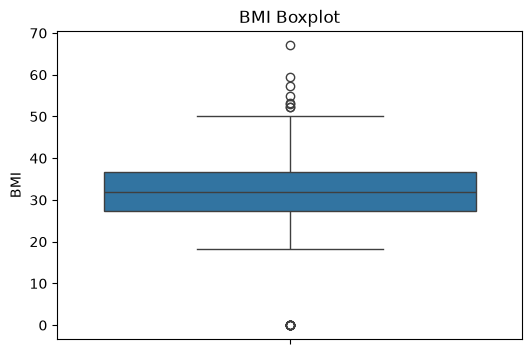

In [59]:
# Create a standalone boxplot for BMI
plt.figure(figsize=(6, 4))
sns.boxplot(y=df["BMI"])
plt.title("BMI Boxplot")
plt.ylabel("BMI")
plt.show()

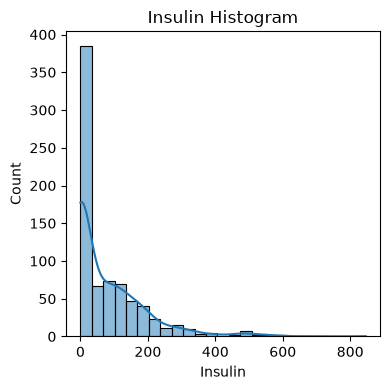

In [63]:
plt.figure(figsize=(4,4))
sns.histplot(df["Insulin"], bins=25, kde=True)
plt.title("Insulin Histogram")
plt.tight_layout()
plt.show()